display range: 0 - 4040 (fixed for all channels)


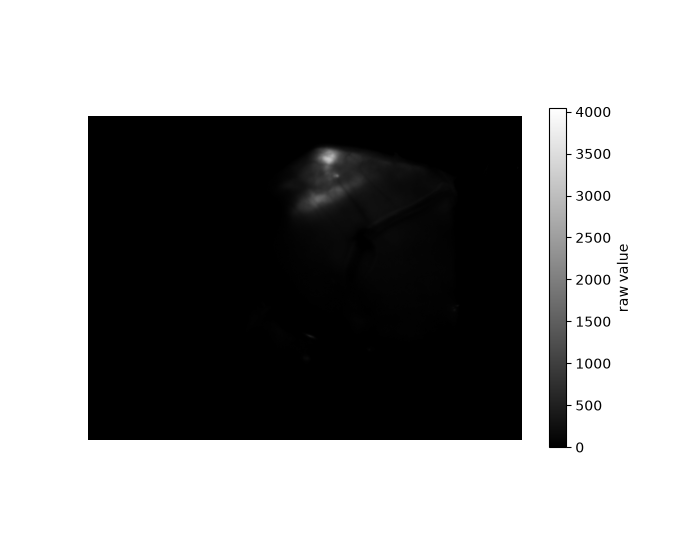

In [26]:
# --- shared setup (self-contained: this cell runs on its own) -----------------
%matplotlib widget
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

CUBE = "/Users/zmkoyan/User Files/multi-excitation-hsi-in-vivo-rats/Data/Raw/Rat_Cubes/12.09/Rat_1/Left_leg/Concatenated_Cube/Rat_1_Left_leg_concatenated.im3"


def resolve(cube):
    """Absolute paths are used as-is; relative ones are taken from the repo root."""
    p = Path(cube)
    if p.is_absolute():
        return p
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / "Data").is_dir():
            return folder / cube
    raise FileNotFoundError(f"could not find a Data/ folder above {Path.cwd()}")


def load_cube(cube):
    """Load an .im3 as (C, Y, X) uint16. Cached per path, so whichever cell runs
    first pays the ~2 s load and the other reuses it."""
    path = resolve(cube)
    cache = globals().setdefault("_CUBE_CACHE", {})
    if str(path) in cache:
        return cache[str(path)]
    if not path.exists():
        near = sorted(path.parent.glob("*.im3"))[:6] or sorted(
            resolve("Data/Raw").rglob("*.im3"))[:6]
        raise FileNotFoundError(f"{path} not found.\nNearby:\n  "
                                + "\n  ".join(str(q) for q in near))
    # Must happen BEFORE the first bioio import: once the JVM starts the Maven
    # repository list is frozen. maven.scijava.org is unreachable on this
    # network, so point scyjava at the OME Artifactory instead.
    os.environ.setdefault("JAVA_HOME", "/opt/homebrew/opt/openjdk")
    import scyjava.config as cfg

    cfg._repositories.pop("scijava.public", None)
    cfg.add_repositories({"ome": "https://artifacts.openmicroscopy.org/artifactory/maven"})
    from bioio import BioImage
    import bioio_bioformats

    arr = BioImage(str(path), reader=bioio_bioformats.Reader).get_image_data("CYX")
    cache[str(path)] = arr
    print(f"loaded {path.name}: {arr.shape} {arr.dtype}")
    return arr


data = load_cube(CUBE)
C, H, W = data.shape

# =============================================================================
# Channel browser: step through the cube with Prev / Next / slider / play.
#
# With neither box ticked: one fixed grey scale for the whole cube, so a given
# raw value is always the same shade and dim channels genuinely look dim.
#
# "per-channel min-max" stretches each channel between its own min and max.
# "per-channel 1-99%" stretches between its 1st and 99th percentile instead and
# clips the rest - robust where min/max are set by outliers, which they are here:
# the camera clips at 4040 counts, so most channels share the same maximum and
# min-max barely distinguishes them. The two boxes are mutually exclusive.
#
# Only the display range ever changes - the pixel values are never touched.
# =============================================================================
VMIN, VMAX = int(data.min()), int(data.max())
PCTS = (1.0, 99.0)                           # bounds used by the percentile box
print(f"display range: {VMIN} - {VMAX} (fixed for all channels)")

slider = widgets.IntSlider(value=0, min=0, max=C - 1, step=1, description="channel",
                           continuous_update=False,
                           layout=widgets.Layout(width="320px"))
prev_btn = widgets.Button(description="< Prev", layout=widgets.Layout(width="90px"))
next_btn = widgets.Button(description="Next >", layout=widgets.Layout(width="90px"))
play = widgets.Play(value=0, min=0, max=C - 1, step=1, interval=300)
widgets.jslink((play, "value"), (slider, "value"))       # play drives the slider
normalise = widgets.Checkbox(value=False, description="per-channel min-max",
                             indent=False, layout=widgets.Layout(width="190px"))
percentile = widgets.Checkbox(value=False, description=f"per-channel {PCTS[0]:g}-{PCTS[1]:g}%",
                              indent=False, layout=widgets.Layout(width="170px"))

# Percentiles need the channel sorted, which costs ~50 ms on a 1.4 Mpx channel -
# too slow to redo on every slider tick, so each channel is worked out once.
_pct_cache = {}


def channel_bounds(index):
    if index not in _pct_cache:
        _pct_cache[index] = tuple(float(v) for v in np.percentile(data[index], PCTS))
    return _pct_cache[index]

# Re-running this cell replaces its own figure and leaves any other cell's alone.
# The figure is keyed by name, so a re-run reclaims the previous one instead of
# leaving a second canvas behind - that is what produces duplicated images.
VIEWER_FIG = "explore: channel browser"
if plt.fignum_exists(VIEWER_FIG):
    plt.close(VIEWER_FIG)
plt.ioff()                                   # don't auto-display; we embed it below
_viewer_fig, _viewer_ax = plt.subplots(num=VIEWER_FIG, figsize=(7, 5.5))
_viewer_fig.canvas.header_visible = False
_viewer_im = _viewer_ax.imshow(data[0], cmap="gray", vmin=VMIN, vmax=VMAX)
_viewer_ax.axis("off")
_viewer_cbar = _viewer_fig.colorbar(_viewer_im, ax=_viewer_ax, shrink=0.8)
_viewer_cbar.set_label("raw value")


def render(_change=None):
    """Update the existing image in place - nothing is ever re-displayed."""
    plane = data[slider.value]
    lo, hi = int(plane.min()), int(plane.max())

    # Ticking a box shows the NORMALISED channel: raw values are mapped onto
    # 0 - 1 by (x - bound_lo) / (bound_hi - bound_lo) and the colorbar becomes
    # that 0 - 1 scale. The title says which raw values 0 and 1 stand for.
    if percentile.value:
        bound_lo, bound_hi = channel_bounds(slider.value)
        tag = f"{PCTS[0]:g}-{PCTS[1]:g}%"
    elif normalise.value:
        bound_lo, bound_hi = float(lo), float(hi)
        tag = "min-max"
    else:
        bound_lo = bound_hi = None

    if bound_lo is None:
        _viewer_im.set_data(plane)
        _viewer_im.set_clim(VMIN, VMAX)
        _viewer_cbar.set_label("raw value")
        _viewer_ax.set_title(f"channel {slider.value} / {C - 1}"
                             f"    raw values    min={lo}  max={hi}"
                             f"    [fixed {VMIN} - {VMAX}]")
    else:
        span = bound_hi - bound_lo
        normed = np.clip((plane.astype(np.float32) - bound_lo) / (span if span > 0 else 1.0),
                         0.0, 1.0)
        _viewer_im.set_data(normed)
        _viewer_im.set_clim(0.0, 1.0)
        _viewer_cbar.set_label(f"normalised ({tag})")
        clipped = "" if percentile.value is False else \
            f"    clipped: {100 * float(np.mean((plane < bound_lo) | (plane > bound_hi))):.1f}%"
        _viewer_ax.set_title(f"channel {slider.value} / {C - 1}    [{tag}]"
                             f"    0 = {bound_lo:g}   1 = {bound_hi:g}"
                             f"    (raw min={lo}  max={hi}){clipped}")
    _viewer_fig.canvas.draw_idle()


def step(delta):
    def handler(_btn):
        slider.value = (slider.value + delta) % C        # wraps around
    return handler


prev_btn.on_click(step(-1))
next_btn.on_click(step(+1))
def on_mode(change):
    """Keep the two stretch boxes mutually exclusive, then redraw."""
    if change["new"]:
        other = percentile if change["owner"] is normalise else normalise
        other.value = False
    render()


slider.observe(render, names="value")
normalise.observe(on_mode, names="value")
percentile.observe(on_mode, names="value")

display(widgets.VBox([widgets.HBox([prev_btn, next_btn, slider, play]),
                      widgets.HBox([normalise, percentile])]))
display(_viewer_fig.canvas)
render()


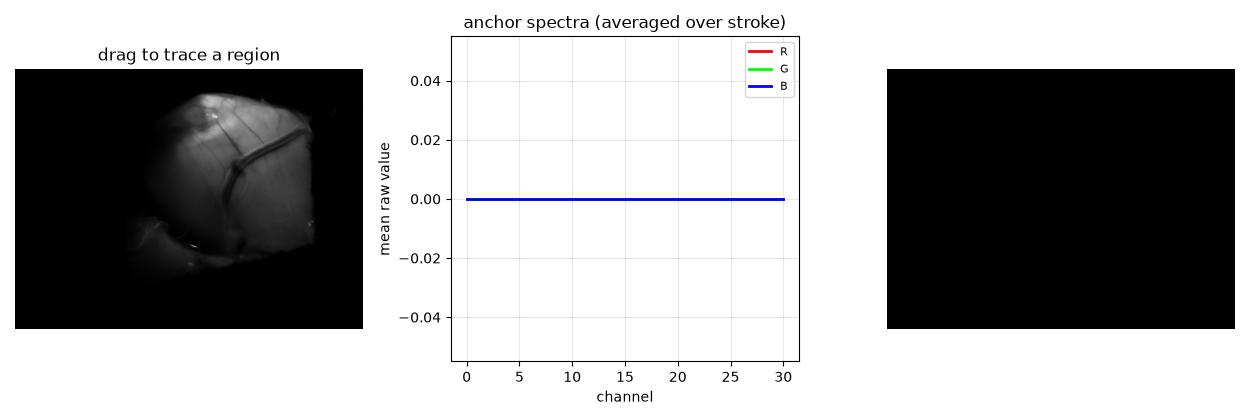

In [ ]:
# --- shared setup (self-contained: this cell runs on its own) -----------------
%matplotlib widget
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import ipywidgets as widgets
from IPython.display import display

CUBE = "/Users/zmkoyan/User Files/multi-excitation-hsi-in-vivo-rats/Data/Raw/Rat_Cubes/12.09/Rat_1/Left_leg/Distinct_Cubes/white_4exp.im3"


def resolve(cube):
    """Absolute paths are used as-is; relative ones are taken from the repo root."""
    p = Path(cube)
    if p.is_absolute():
        return p
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / "Data").is_dir():
            return folder / cube
    raise FileNotFoundError(f"could not find a Data/ folder above {Path.cwd()}")


def load_cube(cube):
    """Load an .im3 as (C, Y, X) uint16. Cached per path, so whichever cell runs
    first pays the ~2 s load and the other reuses it."""
    path = resolve(cube)
    cache = globals().setdefault("_CUBE_CACHE", {})
    if str(path) in cache:
        return cache[str(path)]
    if not path.exists():
        near = sorted(path.parent.glob("*.im3"))[:6] or sorted(
            resolve("Data/Raw").rglob("*.im3"))[:6]
        raise FileNotFoundError(f"{path} not found.\nNearby:\n  "
                                + "\n  ".join(str(q) for q in near))
    # Must happen BEFORE the first bioio import: once the JVM starts the Maven
    # repository list is frozen. maven.scijava.org is unreachable on this
    # network, so point scyjava at the OME Artifactory instead.
    os.environ.setdefault("JAVA_HOME", "/opt/homebrew/opt/openjdk")
    import scyjava.config as cfg

    cfg._repositories.pop("scijava.public", None)
    cfg.add_repositories({"ome": "https://artifacts.openmicroscopy.org/artifactory/maven"})
    from bioio import BioImage
    import bioio_bioformats

    arr = BioImage(str(path), reader=bioio_bioformats.Reader).get_image_data("CYX")
    cache[str(path)] = arr
    print(f"loaded {path.name}: {arr.shape} {arr.dtype}")
    return arr


data = load_cube(CUBE)
C, H, W = data.shape

# =============================================================================
# Spectral endmember mapping: DRAW three reference strokes -> R / G / B map.
#
# Every pixel of the cube is a C-dimensional vector (its spectrum). Drag the
# cursor across the greyscale image to trace a region: every pixel under the
# stroke is collected and averaged PER CHANNEL into one anchor spectrum. Every
# pixel in the cube is then coloured by which anchor it is closest to.
#
# Pick a colour, then click or drag as many times as you like: every stroke ADDS
# to that colour and the colour stays where you put it. Right-drag rubs pixels
# out again; "Clear colour" empties the armed one. "brush px" is the width of the
# round brush: a click selects a disk that wide (brush 15 is ~177 pixels), a drag
# sweeps a band that wide. Strokes pile onto the SAME colour:
# the pixels are unioned (overlaps counted once) and the colour stops advancing,
# so one reference can be traced from several separate patches.
# A single click drops a dot of the current brush width. Averaging many pixels
# is the point: one pixel alone carries full sensor noise.
# =============================================================================
X = data.reshape(C, -1).T.astype(np.float32)        # (P, C): one spectrum per row
# Four endmembers: three tissue classes plus a background one painted black, so
# dark surroundings are not forced into a colour they do not belong to.
K = 4
COLORS = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [0, 0, 0]], dtype=np.float32)
NAMES = ["R", "G", "B", "bg"]
CSS = ["red", "green", "blue", "black"]
EPS = 1e-12


# --- distance in spectral vector space ---------------------------------------
def spectral_distance(X, E, metric):
    """X (P, C) pixels, E (K, C) endmembers -> (P, K) distances."""
    if metric == "SAM (angle)":
        # Spectral Angle Mapper: angle between vectors, ignores overall
        # brightness. Two pixels of the same tissue lit differently have the
        # same SHAPE of spectrum, so SAM calls them identical.
        Xn = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), EPS)
        En = E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), EPS)
        return np.arccos(np.clip(Xn @ En.T, -1.0, 1.0))          # radians
    # Euclidean: straight-line distance, DOES depend on brightness.
    # Expanded as ||x-e||^2 = ||x||^2 - 2 x.e + ||e||^2 so only the (P, K) result
    # is allocated; broadcasting X - E would need P*K*C floats (~0.5 GB on a
    # 1040x1392 cube).
    d2 = (X * X).sum(1)[:, None] - 2.0 * (X @ E.T) + (E * E).sum(1)[None, :]
    return np.sqrt(np.maximum(d2, 0.0))


# --- turn a drawn polyline into the set of pixels underneath it ---------------
def stroke_pixels(xs, ys, width):
    """Polyline in data coords -> unique integer (y, x) pixel indices.

    Segments are walked in half-pixel steps so no pixel is skipped on a diagonal,
    then the trace is thickened to `width` with a disk-shaped brush."""
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    if xs.size < 2:                                   # a plain click
        px, py = np.round(xs).astype(int), np.round(ys).astype(int)
    else:
        steps = np.maximum(np.ceil(np.hypot(np.diff(xs), np.diff(ys)) / 0.5), 1).astype(int)
        cx, cy = [], []
        for i, n in enumerate(steps):
            t = np.linspace(0.0, 1.0, n + 1)
            cx.append(xs[i] + t * (xs[i + 1] - xs[i]))
            cy.append(ys[i] + t * (ys[i + 1] - ys[i]))
        px = np.round(np.concatenate(cx)).astype(int)
        py = np.round(np.concatenate(cy)).astype(int)

    r = (int(width) - 1) // 2
    if r > 0:
        dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
        disk = (dy ** 2 + dx ** 2) <= r * r + 1e-9    # round brush, not square
        py = (py[:, None] + dy[disk][None, :]).ravel()
        px = (px[:, None] + dx[disk][None, :]).ravel()

    py = np.clip(py, 0, H - 1)
    px = np.clip(px, 0, W - 1)
    flat = np.unique(py.astype(np.int64) * W + px.astype(np.int64))
    return (flat // W).astype(int), (flat % W).astype(int)


# --- sensible starting points so the cell shows something on first run -------
def auto_endmembers(k=K, stride=7):
    """Greedy max-min search over signal-bearing pixels.

    Dark background and dead pixels are excluded first: a zero-norm spectrum sits
    at 90 degrees from everything (itself included), so a plain max-min search
    would keep re-picking the same worthless pixel."""
    S = X[::stride]
    n = np.linalg.norm(S, axis=1)
    keep = np.flatnonzero(n > np.percentile(n, 60))
    S, n = S[keep], n[keep]
    Sn = S / np.maximum(n[:, None], EPS)
    picked = [int(np.argmax(n))]
    for _ in range(k - 1):
        d = np.arccos(np.clip(Sn @ Sn[picked].T, -1.0, 1.0)).min(axis=1)
        d[picked] = -1.0
        picked.append(int(np.argmax(d)))
    return [(int(keep[i] * stride) // W, int(keep[i] * stride) % W) for i in picked]


# --- controls -----------------------------------------------------------------
arm = widgets.ToggleButtons(options=list(zip(NAMES, range(K))), value=0,
                            description="drawing into:")
brush = widgets.IntSlider(value=15, min=1, max=41, step=2, description="brush \u2300 px",
                          continuous_update=False, layout=widgets.Layout(width="290px"))
metric = widgets.Dropdown(options=["SAM (angle)", "Euclidean"], value="SAM (angle)",
                          description="metric", layout=widgets.Layout(width="250px"))
mode = widgets.Dropdown(options=["hard (nearest wins)", "soft (blend by 1/d)"],
                        value="hard (nearest wins)", description="mode",
                        layout=widgets.Layout(width="250px"))
modulate = widgets.Checkbox(value=False, description="shade by pixel brightness")
clear_btn = widgets.Button(description="Clear colour")
reset = widgets.Button(description="Reset all")
status = widgets.HTML()

# selection[k] = (ys, xs) pixel indices averaged into endmember k, and paths[k]
# the polylines that produced them (several, when "add to selection" is on).
_seeds = auto_endmembers()
selection = [stroke_pixels([x], [y], brush.value) for y, x in _seeds]
paths = [[([x], [y])] for y, x in _seeds]


def redraw_trace(k):
    """One artist per colour, so several strokes are joined by NaN breaks."""
    xs, ys = [], []
    for path_x, path_y in paths[k]:
        xs += list(path_x) + [np.nan]
        ys += list(path_y) + [np.nan]
    traces[k].set_data(xs, ys)


def merge_pixels(old, new):
    """Union of two pixel sets, kept unique via flat indices."""
    flat = np.unique(np.concatenate([old[0] * W + old[1], new[0] * W + new[1]]))
    return (flat // W).astype(int), (flat % W).astype(int)


def drop_pixels(old, gone):
    """`old` minus `gone` - what a right-drag rubs out."""
    flat = np.setdiff1d(old[0] * W + old[1], gone[0] * W + gone[1])
    return (flat // W).astype(int), (flat % W).astype(int)

# --- figure built ONCE, then updated in place --------------------------------
# Keyed by name so a re-run reclaims this cell's figure rather than stacking a
# second canvas into the output (the cause of duplicated images).
PICKER_FIG = "explore: endmember picker"
if plt.fignum_exists(PICKER_FIG):
    plt.close(PICKER_FIG)
plt.ioff()                                   # don't auto-display; we embed it below
fig, axes = plt.subplots(1, 3, num=PICKER_FIG, figsize=(12.5, 4.2))
_picker_fig = fig
fig.canvas.header_visible = False

axes[0].imshow(data.mean(axis=0), cmap="gray")
axes[0].set_title("drag to trace a region")
axes[0].axis("off")
# A white halo keeps every trace legible on the grey image, the black one
# especially.
# No markers: a marker under a path effect is re-rendered twice per point and
# costs ~7.7 ms a frame, against 0.08 ms for a plain line.
traces = [axes[0].plot([], [], "-", color=c, lw=2.2, solid_capstyle="round",
                       path_effects=[pe.withStroke(linewidth=4.2, foreground="white")])[0]
          for c in CSS]

lines = [axes[1].plot(np.arange(C), np.zeros(C), color=c, lw=2, label=n)[0]
         for n, c in zip(NAMES, COLORS)]
axes[1].set_xlabel("channel")
axes[1].set_ylabel("mean raw value")
axes[1].set_title("anchor spectra (averaged over stroke)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

art = axes[2].imshow(np.zeros((H, W, 3)))
axes[2].axis("off")
fig.tight_layout()


def update(_change=None):
    bare = [NAMES[k] for k in range(K) if len(selection[k][0]) == 0]
    if bare:                                 # an empty endmember has no spectrum
        status.value = (f"nothing selected for {', '.join(bare)}"
                        " &mdash; draw on the image first")
        return
    E = np.stack([data[:, ys, xs].mean(axis=1) for ys, xs in selection]).astype(np.float32)

    d = spectral_distance(X, E, metric.value)
    labels = d.argmin(axis=1)
    if mode.value.startswith("hard"):
        rgb = COLORS[labels]                              # pure R/G/B per pixel
    else:
        w = 1.0 / (d + 1e-6)
        w /= w.sum(axis=1, keepdims=True)                 # inverse-distance blend
        rgb = w @ COLORS

    rgb = rgb.reshape(H, W, 3).copy()
    if modulate.value:                                    # keep anatomy visible
        inten = X.mean(axis=1)
        inten = np.clip(inten / max(np.percentile(inten, 99), EPS), 0, 1)
        rgb *= inten.reshape(H, W, 1)
    rgb[np.linalg.norm(X, axis=1).reshape(H, W) == 0] = 0  # dead pixels -> black

    for k in range(K):
        lines[k].set_ydata(E[k])
    axes[1].relim()
    axes[1].autoscale_view()
    art.set_data(rgb)
    axes[2].set_title(f"{metric.value}  |  {mode.value.split()[0]}")

    status.value = "<br>".join(
        f"<b style='color:{css}'>{n}</b>: {len(selection[k][0])} px averaged"
        f" &nbsp; -> &nbsp; {100 * (labels == k).mean():.1f}% of image"
        for k, (n, css) in enumerate(zip(NAMES, CSS)))
    fig.canvas.draw_idle()


# --- freehand drawing ---------------------------------------------------------
# A full redraw of this figure costs ~80 ms (three panels over a 1.45 Mpx cube),
# far too slow to run on every mouse-move. So the image panel is cached as a
# bitmap when the stroke starts, and each motion event only re-blits that cache
# plus the stroke line.
draw = {"on": False, "xs": [], "ys": [], "bg": None, "px": [], "n": 0, "ticks": 0,
        "erase": False}


def busy():
    """True while the toolbar's pan/zoom is active, so drawing doesn't fight it."""
    tb = getattr(fig.canvas, "toolbar", None)
    return bool(getattr(tb, "mode", ""))


def on_press(event):
    """Left drag adds pixels to the armed colour, right drag rubs them out."""
    if event.inaxes is not axes[0] or event.button not in (1, 3) or busy():
        return
    fig.canvas.draw()                        # one full redraw, then blit from here
    try:
        bg = fig.canvas.copy_from_bbox(axes[0].bbox)
    except Exception:                        # backend without blit support
        bg = None
    # The pixel under the press counts straight away, so a plain click selects.
    first = stroke_pixels([event.xdata], [event.ydata], brush.value)
    draw.update(on=True, xs=[event.xdata], ys=[event.ydata], bg=bg,
                px=[first], n=len(first[0]), ticks=0, erase=event.button == 3)


def on_motion(event):
    if not draw["on"] or event.inaxes is not axes[0] or event.xdata is None:
        return
    # Everything the cursor sweeps over is collected as it moves: the segment
    # just travelled is converted to pixels now, not at release.
    x0, y0 = draw["xs"][-1], draw["ys"][-1]
    draw["xs"].append(event.xdata)
    draw["ys"].append(event.ydata)
    segment = stroke_pixels([x0, event.xdata], [y0, event.ydata], brush.value)
    draw["px"].append(segment)
    draw["n"] += len(segment[0])
    draw["ticks"] += 1
    if draw["ticks"] % 8 == 0:               # throttled live count
        status.value = (f"<b style='color:{['red','green','blue'][arm.value]}'>"
                        f"{NAMES[arm.value]}</b>: selecting ~{draw['n']} px ...")
    trace = traces[arm.value]
    live_x, live_y = [], []
    for path_x, path_y in paths[arm.value]:               # strokes already kept
        live_x += list(path_x) + [np.nan]
        live_y += list(path_y) + [np.nan]
    trace.set_data(live_x + draw["xs"], live_y + draw["ys"])   # live feedback
    if draw["bg"] is not None:
        try:
            fig.canvas.restore_region(draw["bg"])
            axes[0].draw_artist(trace)
            fig.canvas.blit(axes[0].bbox)
            return
        except Exception:
            draw["bg"] = None
    fig.canvas.draw_idle()


def on_release(event):
    if not draw["on"]:
        return
    draw["on"] = False
    k = arm.value
    # Every segment swept during the drag (duplicates collapse in the merge).
    picked = (np.concatenate([seg[0] for seg in draw["px"]]),
              np.concatenate([seg[1] for seg in draw["px"]]))
    if draw["erase"]:
        selection[k] = drop_pixels(selection[k], picked)
    else:
        selection[k] = merge_pixels(selection[k], picked)
        paths[k].append((draw["xs"], draw["ys"]))
    # The colour is NEVER advanced automatically - switch R/G/B by hand.
    redraw_trace(k)
    update()


def on_clear(_btn):
    """Empty just the colour that is armed."""
    k = arm.value
    selection[k] = (np.array([], dtype=int), np.array([], dtype=int))
    paths[k] = []
    redraw_trace(k)
    update()


def on_reset(_btn):
    for k, (y, x) in enumerate(auto_endmembers()):
        selection[k] = stroke_pixels([x], [y], brush.value)
        paths[k] = [([x], [y])]
        redraw_trace(k)
    update()


fig.canvas.mpl_connect("button_press_event", on_press)
fig.canvas.mpl_connect("motion_notify_event", on_motion)
fig.canvas.mpl_connect("button_release_event", on_release)
clear_btn.on_click(on_clear)
reset.on_click(on_reset)
for w_ in (metric, mode, modulate):
    w_.observe(update, names="value")

for k in range(K):
    redraw_trace(k)                          # show where the seeds landed

display(widgets.VBox([arm, widgets.HBox([brush, clear_btn, reset]),
                      widgets.HBox([metric, mode]), modulate, status]))
display(fig.canvas)
update()


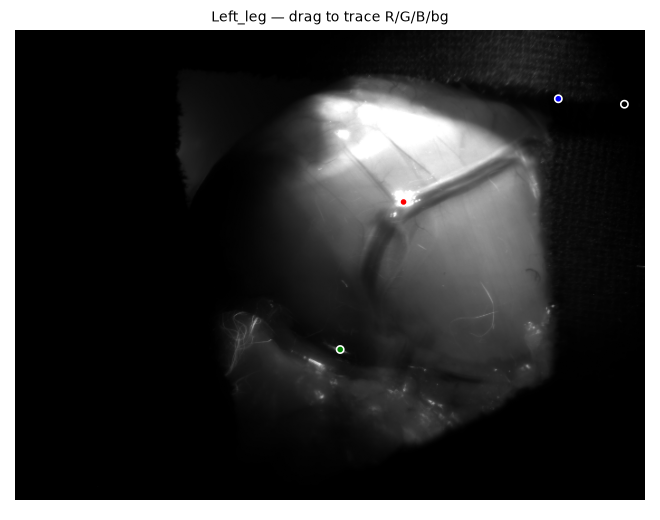

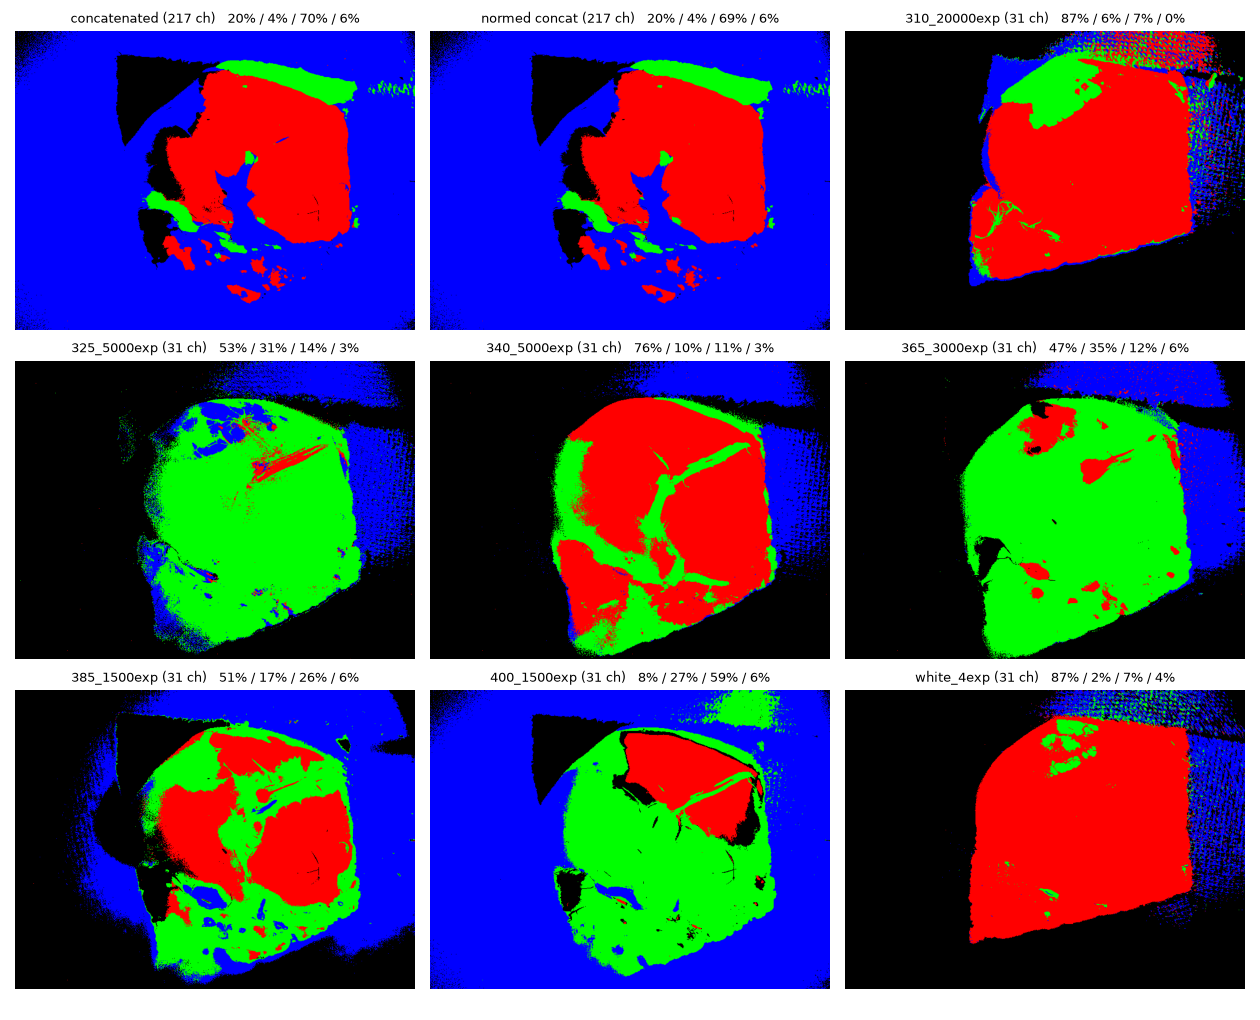

In [48]:
# =============================================================================
# One set of points, one decomposition per cube of a leg.
#
# Give a leg folder. Drag three strokes on the grayscale picker, then press
# "Decompose": the SAME pixel locations are decomposed separately in every cube
# of that leg — the concatenated cube, the normalised concatenated cube, and each
# of the 7 per-excitation cubes, nine maps in all. Each cube supplies its OWN
# values at those pixels, so every map is built from that cube's endmembers
# alone. Side by side they show which setup separates the tissue best.
#
# Zooming is matplotlib's own: the picker carries the same toolbar as the maps
# figure, so its rubber-band Zoom and Home behave exactly as they do there. While
# a toolbar tool is switched on it owns the mouse, and drawing then refuses with a
# message instead of quietly doing nothing. Middle-drag pans.
#
# Selecting: pick a colour, then click or drag as many times as you like — every
# stroke ADDS to that colour, nothing is ever replaced. "brush" is the width of
# the round brush in pixels, so one click selects a disk that wide (brush 15 is
# ~177 pixels) and a drag sweeps a band that wide. Right-drag rubs pixels out
# again, "Clear colour" empties the current one, and the colour buttons only
# change when you press them.
#
# Drawing never triggers a decomposition: the strokes live on their own small
# figure, and the nine maps are only rebuilt when the button is pressed.
#
# Every pixel is coloured by which of the four reference spectra it is nearest
# to, in that cube's own channel space (31 channels for a distinct cube, 217 for
# a concatenated one). The fourth, "bg", is drawn black: trace the background
# with it so that dark surroundings are not forced into R, G or B. As in the picker cell above, a stroke averages
# every pixel it covers: one pixel alone carries full sensor noise.
# =============================================================================
%matplotlib widget
import mmap
import re
import struct
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import ipywidgets as widgets
from IPython.display import display

LEG = "/Users/zmkoyan/User Files/multi-excitation-hsi-in-vivo-rats/Data/Raw/Rat_Cubes/12.09/Rat_1/Left_leg"

# Four references: three tissue classes plus a background one that paints black,
# so dark surroundings stop being forced into a colour they do not belong to.
K = 4
NAMES = ["R", "G", "B", "bg"]
CSS = ["red", "green", "blue", "black"]
RGB = np.array([[1.0, 0, 0], [0, 1.0, 0], [0, 0, 1.0], [0, 0, 0]])
STRIDE = 2                                   # classify every STRIDE-th pixel
EPS = 1e-12


# --- .im3 access: a strided cube for the maps, exact pixels for the anchors ---
# Records are: int32 nameLen, name, int32 recLen (payload + 8), int32 type,
# payload. Containers (type 0) open with int32 1, int32 nChildren. The DataSet's
# "Data" record holds int32 3, X, Y, C then X*Y*C uint16 pixels, arranged
# (Y, X, C) — so one pixel's whole spectrum is contiguous on disk.
def _record(buf, p):
    n, = struct.unpack_from("<i", buf, p)
    name = bytes(buf[p + 4:p + 4 + n]).decode("utf-8", "replace")
    p += 4 + n
    length, rtype = struct.unpack_from("<ii", buf, p)
    return (name, rtype, p + 8, length - 8), p + 8 + length - 8


def _children(buf, rec):
    p, end, out = rec[2] + 8, rec[2] + rec[3], []
    while p < end - 8:
        child, p = _record(buf, p)
        out.append(child)
    return out


def _find(buf, rec, name):
    for child in _children(buf, rec):
        if child[0] == name:
            return child
    raise KeyError(f"no {name!r} record in {rec[0]!r}")


def im3_open(path):
    """Where the pixels live in an .im3, without reading any of them."""
    path = Path(path)
    with open(path, "rb") as fh:
        with mmap.mmap(fh.fileno(), 0, access=mmap.ACCESS_READ) as mm:
            if struct.unpack_from("<i", mm, 0)[0] != 1985:
                raise ValueError(f"{path} is not an .im3 (bad cookie)")
            p, top = 4, []
            while p < len(mm) - 16:
                rec, p = _record(mm, p)
                top.append(rec)
            inner = _children(mm, _find(mm, top[-1], "DataSet"))[0]
            data = _find(mm, inner, "Data")
            _, width, height, channels = struct.unpack_from("<iiii", mm, data[2])
    return {"path": path, "offset": data[2] + 16,
            "W": width, "H": height, "C": channels}


def im3_strided(meta, stride=STRIDE):
    """Every stride-th pixel as a contiguous (C, y, x) uint16 array.

    The file is mapped, not read: only the pages the slice touches are paged in,
    and the views must be dropped before the mmap closes.
    """
    with open(meta["path"], "rb") as fh:
        with mmap.mmap(fh.fileno(), 0, access=mmap.ACCESS_READ) as mm:
            flat = np.frombuffer(mm, dtype="<u2", offset=meta["offset"],
                                 count=meta["W"] * meta["H"] * meta["C"])
            cube = flat.reshape(meta["H"], meta["W"], meta["C"])
            sub = np.ascontiguousarray(cube[::stride, ::stride].transpose(2, 0, 1))
            del cube, flat                   # mmap cannot close while views exist
    return sub


def pixel_spectrum(meta, ys, xs):
    """Mean raw spectrum of the given full-resolution pixels, read from disk.

    Pixels are gathered straight out of the mapped file: the layout is (Y, X, C),
    so row `y * W + x` of the mapped (H*W, C) view is that pixel's spectrum and
    only the pages a stroke actually touches are read.
    """
    width, channels = meta["W"], meta["C"]
    index = np.asarray(ys, dtype=np.int64) * width + np.asarray(xs, dtype=np.int64)
    with open(meta["path"], "rb") as fh:
        with mmap.mmap(fh.fileno(), 0, access=mmap.ACCESS_READ) as mm:
            view = np.frombuffer(mm, dtype="<u2", offset=meta["offset"],
                                 count=meta["W"] * meta["H"] * channels)
            picked = view.reshape(-1, channels)[index].astype(np.float32)
            del view                         # mmap cannot close while views exist
    return picked.mean(axis=0)


def stroke_pixels(xs, ys, width_px, shape):
    """Polyline in data coords -> unique integer (y, x) indices under the brush.

    Segments are walked in half-pixel steps so a diagonal skips no pixel, then
    the trace is thickened to `width_px` with a disk-shaped brush.
    """
    height, w_img = shape
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if xs.size < 2:                                   # a plain click
        px, py = np.round(xs).astype(int), np.round(ys).astype(int)
    else:
        steps = np.maximum(np.ceil(np.hypot(np.diff(xs), np.diff(ys)) / 0.5), 1).astype(int)
        cx, cy = [], []
        for i, n in enumerate(steps):
            t = np.linspace(0.0, 1.0, n + 1)
            cx.append(xs[i] + t * (xs[i + 1] - xs[i]))
            cy.append(ys[i] + t * (ys[i + 1] - ys[i]))
        px = np.round(np.concatenate(cx)).astype(int)
        py = np.round(np.concatenate(cy)).astype(int)

    r = (int(width_px) - 1) // 2
    if r > 0:
        dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
        disk = (dy ** 2 + dx ** 2) <= r * r + 1e-9    # round brush, not square
        py = (py[:, None] + dy[disk][None, :]).ravel()
        px = (px[:, None] + dx[disk][None, :]).ravel()

    py = np.clip(py, 0, height - 1)
    px = np.clip(px, 0, w_img - 1)
    flat = np.unique(py.astype(np.int64) * w_img + px.astype(np.int64))
    return (flat // w_img).astype(int), (flat % w_img).astype(int)


def band_order_key(path):
    """Excitation ascending, white light last (filenames are irregular)."""
    m = re.match(r"\s*(\d{3})", path.stem)
    return (0, int(m.group(1)), path.stem.lower()) if m else (1, 0, path.stem.lower())


def leg_cubes(leg):
    """(title, .im3 path) for every cube of a leg: concatenated, normed, distinct."""
    leg = Path(leg)
    out = []
    for folder, tag in (("Concatenated_Cube", "concatenated"),
                        ("Normed_Concatenated_Cube", "normed concat")):
        found = sorted((leg / folder).glob("*.im3")) if (leg / folder).is_dir() else []
        out += [(tag, p) for p in found[:1]]
    distinct = sorted((leg / "Distinct_Cubes").glob("*.im3"), key=band_order_key) \
        if (leg / "Distinct_Cubes").is_dir() else []
    out += [(p.stem, p) for p in distinct if not p.name.startswith(".")]
    if not out:
        raise FileNotFoundError(f"no .im3 cubes under {leg}")
    return out


# --- decomposition ------------------------------------------------------------
CHUNK = 65536                                # pixels per matmul block


def classify(sub, E, metric):
    """Label every pixel of a cube by which reference spectrum it is nearest to.

    Worked in blocks: the float32 copy of a whole 217-channel cube would be
    1.3 GB, while one block is a few MB. SAM compares only the SHAPE of the
    spectrum (brightness drops out); Euclidean does not.
    """
    channels = sub.shape[0]
    flat = sub.reshape(channels, -1)
    total = flat.shape[1]
    labels = np.empty(total, dtype=np.uint8)
    dead = np.empty(total, dtype=bool)
    En = E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), EPS)
    e2 = (E * E).sum(axis=1)
    for start in range(0, total, CHUNK):
        block = flat[:, start:start + CHUNK].T.astype(np.float32)
        norms = np.linalg.norm(block, axis=1)
        if metric.startswith("SAM"):
            # nearest angle == largest cosine, so the arccos is unnecessary
            unit = block / np.maximum(norms[:, None], EPS)
            labels[start:start + CHUNK] = (unit @ En.T).argmax(axis=1)
        else:
            # ||x-e||^2 = ||x||^2 - 2 x.e + ||e||^2 keeps only the (n, K) result
            d2 = (block * block).sum(1)[:, None] - 2.0 * (block @ E.T) + e2[None, :]
            labels[start:start + CHUNK] = d2.argmin(axis=1)
        dead[start:start + CHUNK] = norms == 0
    shape = sub.shape[1:]
    return labels.reshape(shape), dead.reshape(shape)


def auto_points(sub, k=K):
    """Greedy max-min (spectral angle) seeds, in full-resolution coordinates.

    Dark pixels are dropped first: a zero-norm spectrum sits at 90 degrees from
    everything including itself, so a plain max-min search re-picks it forever.
    """
    channels, _, sub_w = sub.shape
    S = sub.reshape(channels, -1).T.astype(np.float32)
    norms = np.linalg.norm(S, axis=1)
    keep = np.flatnonzero(norms > np.percentile(norms, 60))
    S, norms = S[keep], norms[keep]
    unit = S / np.maximum(norms[:, None], EPS)
    picked = [int(np.argmax(norms))]
    for _ in range(k - 1):
        d = np.arccos(np.clip(unit @ unit[picked].T, -1.0, 1.0)).min(axis=1)
        d[picked] = -1.0
        picked.append(int(np.argmax(d)))
    return [((int(keep[i]) // sub_w) * STRIDE, (int(keep[i]) % sub_w) * STRIDE)
            for i in picked]


# --- controls -----------------------------------------------------------------
# Drawing and decomposing are deliberately separate: a stroke only touches the
# small grayscale figure, so it stays responsive, and the nine maps are rebuilt
# on demand when "Decompose" is pressed.
leg_box = widgets.Text(value=LEG, description="leg", layout=widgets.Layout(width="720px"))
load_btn = widgets.Button(description="Load leg")
arm = widgets.ToggleButtons(options=list(zip(NAMES, range(K))), value=0,
                            description="drawing into:")
brush = widgets.IntSlider(value=15, min=1, max=41, step=2, description="brush \u2300 px",
                          continuous_update=False, layout=widgets.Layout(width="290px"))
hint = widgets.HTML("<i>left-drag adds pixels to the selected colour (they keep adding "
                    "up) &nbsp;|&nbsp; right-drag rubs out &nbsp;|&nbsp; zoom with the "
                    "toolbar as on the maps, middle-drag pans &mdash; switch a toolbar "
                    "tool off again to draw</i>")
clear_btn = widgets.Button(description="Clear colour")
reset_btn = widgets.Button(description="Reset all")
metric = widgets.Dropdown(options=["SAM (angle)", "Euclidean"], value="SAM (angle)",
                          description="metric", layout=widgets.Layout(width="230px"))
shade = widgets.Checkbox(value=False, description="shade by brightness", indent=False,
                         layout=widgets.Layout(width="190px"))
go_btn = widgets.Button(description="Decompose", button_style="primary",
                        layout=widgets.Layout(width="140px"))
status = widgets.HTML()

# selection[k] = (ys, xs) full-resolution pixels averaged into reference k
state = {"metas": [], "subs": [], "inten": [], "titles": [], "sel": [], "shape": None,
         "labels": [], "dead": [], "paths": [[] for _ in range(K)]}
panels = {"pickfig": None, "picker": None, "traces": [], "overlay": None,
          "mapfig": None, "axes": [], "arts": []}
draw = {"on": False, "xs": [], "ys": [], "bg": None, "px": [], "n": 0, "ticks": 0,
        "erase": False, "last": 0.0}
BLIT_INTERVAL = 0.04                         # s between live redraws (~25 fps)
# mode is "draw" while selecting, "zoom" while rubber-banding, "pan" while panning
nav = {"mode": "draw", "x0": 0.0, "y0": 0.0, "lims": None}


def say(message, stale=False):
    counts = "&nbsp;&nbsp;".join(
        f"<b style='color:{CSS[k]}'>{NAMES[k]}</b>: {len(state['sel'][k][0])} px"
        f" ({len(state['paths'][k])} stroke{'s' if len(state['paths'][k]) != 1 else ''})"
        for k in range(K)) if state["sel"] else ""
    flag = " &nbsp;&nbsp; <i>strokes changed — press Decompose</i>" if stale else ""
    status.value = f"{counts} &nbsp;&nbsp; {message}{flag}"


def refresh_overlay():
    """Tint every selected pixel on the picker, so what is chosen is unmistakable."""
    if panels.get("overlay") is None:
        return
    rows, cols = panels["overlay"].get_array().shape[:2]
    mask = np.zeros((rows, cols, 4), dtype=np.uint8)
    for k in range(K):
        ys, xs = state["sel"][k]
        if len(ys) == 0:
            continue
        ry = np.clip(ys // STRIDE, 0, rows - 1)
        rx = np.clip(xs // STRIDE, 0, cols - 1)
        mask[ry, rx, :3] = np.maximum(RGB[k] * 255, 30).astype(np.uint8)
        mask[ry, rx, 3] = 140
    panels["overlay"].set_data(mask)


def redraw_trace(k):
    """One artist per colour, so several strokes are joined by NaN breaks."""
    xs, ys = [], []
    for path_x, path_y in state["paths"][k]:
        xs += list(path_x) + [np.nan]
        ys += list(path_y) + [np.nan]
    panels["traces"][k].set_data(xs, ys)


def merge_pixels(old, new, width):
    """Union of two pixel sets, kept unique via flat indices."""
    flat = np.unique(np.concatenate([old[0] * width + old[1], new[0] * width + new[1]]))
    return (flat // width).astype(int), (flat % width).astype(int)


def drop_pixels(old, gone, width):
    """`old` minus `gone` - what a right-drag rubs out."""
    flat = np.setdiff1d(old[0] * width + old[1], gone[0] * width + gone[1])
    return (flat // width).astype(int), (flat % width).astype(int)


# Canvas handling, which is fussier than it looks. ipympl sends a canvas's image
# once, when its first view initialises, and then only diffs; so
#   * a canvas must be DISPLAYED ONLY AFTER it has been filled in, or the picture
#     the front-end caches is the empty figure, and
#   * a canvas that has already been displayed once must never be displayed
#     again - the second view gets no image and renders as a bare toolbar.
# Hence: running the cell builds both figures from scratch (closing any pair left
# by an earlier run), fills them, and displays each canvas exactly once at the
# end. Pressing "Load leg" makes NO new figures - it clears and repopulates the
# ones already on screen, so those live views just receive the new drawing.
PICK_FIG = "compare: picker"
MAPS_FIG = "compare: decompositions"


def new_figures():
    """Fresh figures for this run of the cell, replacing any earlier pair."""
    for name in (PICK_FIG, MAPS_FIG):
        if plt.fignum_exists(name):
            plt.close(name)
    plt.ioff()                               # canvases are displayed by hand
    pickfig = plt.figure(PICK_FIG, figsize=(6.6, 5.2))
    mapfig = plt.figure(MAPS_FIG, figsize=(12.6, 10.4))
    pickfig.canvas.header_visible = False
    mapfig.canvas.header_visible = False
    # The picker keeps matplotlib's toolbar, exactly like the maps figure: its
    # Zoom draws the familiar rubber band and Home goes back to the full image.
    # While a toolbar tool is active it owns the mouse, so drawing is refused and
    # says so out loud rather than failing silently.
    pickfig.canvas.toolbar_visible = True
    panels.update(pickfig=pickfig, mapfig=mapfig)

    # Only the picker listens for the mouse - the maps never redraw while drawing.
    # The canvas is new here, so the handlers cannot accumulate.
    pickfig.canvas.mpl_connect("button_press_event", on_press)
    pickfig.canvas.mpl_connect("motion_notify_event", on_motion)
    pickfig.canvas.mpl_connect("button_release_event", on_release)


def layout_panels(n_maps):
    """Rebuild the axes inside the existing figures; the canvases stay put."""
    pickfig, mapfig = panels["pickfig"], panels["mapfig"]
    pickfig.clf()
    picker = pickfig.add_subplot(111)
    picker.axis("off")

    cols = 3
    rows = int(np.ceil(n_maps / cols))
    mapfig.clf()
    mapfig.set_size_inches(12.6, 3.4 * rows)
    axes = [mapfig.add_subplot(rows, cols, i + 1) for i in range(n_maps)]
    for ax in axes:
        ax.axis("off")
    panels.update(picker=picker, traces=[], overlay=None, axes=axes, arts=[])


def load_leg(_btn=None):
    """Read every cube of the leg at STRIDE resolution and lay out the panels."""
    cubes = leg_cubes(leg_box.value.strip())
    status.value = f"loading {len(cubes)} cubes ..."
    metas = [im3_open(p) for _, p in cubes]
    shapes = {(m["H"], m["W"]) for m in metas}
    if len(shapes) != 1:
        raise ValueError("cubes of this leg differ in H/W: "
                         + ", ".join(f"{p.name} {m['H']}x{m['W']}"
                                     for (_, p), m in zip(cubes, metas)))
    subs = [im3_strided(m) for m in metas]
    state.update(metas=metas, subs=subs,
                 inten=[s.mean(axis=0) for s in subs],
                 titles=[f"{t} ({m['C']} ch)" for (t, _), m in zip(cubes, metas)],
                 shape=shapes.pop(), labels=[], dead=[])

    layout_panels(len(subs))
    height, width = state["shape"]
    preview = state["inten"][0]
    lo, hi = np.percentile(preview, (1.0, 99.0))      # display stretch only
    panels["picker"].imshow(preview, cmap="gray", vmin=lo, vmax=max(hi, lo + 1),
                            extent=(-0.5, width - 0.5, height - 0.5, -0.5))
    panels["picker"].set_title(f"{Path(leg_box.value.strip()).name} — drag to trace "
                               f"{'/'.join(NAMES)}", fontsize=10)
    panels["pickfig"].tight_layout()
    # A white halo keeps every trace legible on the grey image, the black one
    # especially.
    sub_h, sub_w = subs[0].shape[1:]
    panels["overlay"] = panels["picker"].imshow(
        np.zeros((sub_h, sub_w, 4), dtype=np.uint8), interpolation="nearest",
        extent=(-0.5, width - 0.5, height - 0.5, -0.5))
    panels["traces"] = [panels["picker"].plot(
        [], [], "-o", color=c, lw=1.8, ms=3,
        path_effects=[pe.withStroke(linewidth=3.4, foreground="white")])[0]
        for c in CSS]
    panels["arts"] = [ax.imshow(np.zeros(s.shape[1:] + (3,)))
                      for ax, s in zip(panels["axes"], subs)]
    panels["mapfig"].tight_layout()

    seeds = auto_points(subs[0])
    state["sel"] = [stroke_pixels([x], [y], brush.value, state["shape"]) for y, x in seeds]
    state["paths"] = [[([x], [y])] for y, x in seeds]
    for k in range(K):
        redraw_trace(k)
    refresh_overlay()
    panels["pickfig"].canvas.draw_idle()
    decompose()


def decompose(_btn=None):
    """Rebuild all nine maps: each cube's own spectra at the shared pixels."""
    if not state["subs"]:
        return
    bare = [NAMES[k] for k in range(K) if len(state["sel"][k][0]) == 0]
    if bare:                                 # an empty reference has no spectrum
        say(f"nothing selected for {', '.join(bare)} — draw on the picker first")
        return
    say("decomposing ...")
    labels, dead = [], []
    for meta, sub in zip(state["metas"], state["subs"]):
        E = np.stack([pixel_spectrum(meta, ys, xs) for ys, xs in state["sel"]])
        lab, void = classify(sub, E, metric.value)
        labels.append(lab)
        dead.append(void)
    state.update(labels=labels, dead=dead)
    paint()


def paint(_change=None):
    """Colour the cached labels - instant, so "shade" needs no recomputation."""
    if not state["labels"]:
        return
    for i, labels in enumerate(state["labels"]):
        rgb = RGB[labels]
        if shade.value:
            level = state["inten"][i]
            rgb = rgb * np.clip(level / max(np.percentile(level, 99), EPS), 0, 1)[..., None]
        rgb[state["dead"][i]] = 0.0
        panels["arts"][i].set_data(rgb)
        share = [100.0 * float((labels == k).mean()) for k in range(K)]
        panels["axes"][i].set_title(
            f"{state['titles'][i]}   " + " / ".join(f"{s:.0f}%" for s in share),
            fontsize=9)
    panels["mapfig"].canvas.draw_idle()
    say(f"{metric.value}, maps at 1/{STRIDE} resolution")


# --- zoom / pan ---------------------------------------------------------------
def busy():
    """True while a toolbar tool (zoom / pan) has taken over the mouse."""
    return bool(getattr(getattr(panels["pickfig"].canvas, "toolbar", None), "mode", ""))



def clamp_limits():
    """Keep the view inside the image and refresh."""
    ax = panels["picker"]
    height, width = state["shape"]
    x0, x1 = sorted(ax.get_xlim())
    y1, y0 = sorted(ax.get_ylim())            # y axis is inverted
    span_x = min(x1 - x0, width)
    span_y = min(y0 - y1, height)
    x0 = min(max(x0, -0.5), width - 0.5 - span_x)
    y1 = min(max(y1, -0.5), height - 0.5 - span_y)
    ax.set_xlim(x0, x0 + span_x)
    ax.set_ylim(y1 + span_y, y1)
    panels["pickfig"].canvas.draw_idle()


# --- freehand drawing (picker canvas only) ------------------------------------
def on_press(event):
    """Left drag adds pixels, right drag rubs out, middle drag pans."""
    if event.inaxes is not panels["picker"]:
        return
    if event.button == 2:                          # middle button: pan
        nav.update(mode="pan", x0=event.xdata, y0=event.ydata,
                   lims=(panels["picker"].get_xlim(), panels["picker"].get_ylim()))
        return
    if event.button not in (1, 3):
        return
    if busy():                                     # a toolbar tool owns the mouse
        say("the toolbar's zoom/pan is active — switch it off to draw")
        return
    nav["mode"] = "draw"
    panels["pickfig"].canvas.draw()                # one redraw of the small figure
    try:
        bg = panels["pickfig"].canvas.copy_from_bbox(panels["picker"].bbox)
    except Exception:                              # backend without blit support
        bg = None
    # The pixel under the press counts straight away, so a plain click selects.
    first = stroke_pixels([event.xdata], [event.ydata], brush.value, state["shape"])
    draw.update(on=True, xs=[event.xdata], ys=[event.ydata], bg=bg,
                px=[first], n=len(first[0]), ticks=0, erase=event.button == 3,
                last=0.0)


def on_motion(event):
    if event.inaxes is not panels["picker"] or event.xdata is None:
        return
    if nav["mode"] == "pan":
        (x0, x1), (y0, y1) = nav["lims"]
        dx, dy = event.xdata - nav["x0"], event.ydata - nav["y0"]
        panels["picker"].set_xlim(x0 - dx, x1 - dx)
        panels["picker"].set_ylim(y0 - dy, y1 - dy)
        clamp_limits()
        return
    # Only the traced line is blitted over a cached bitmap, so dragging stays
    # smooth however many maps are on screen.
    if not draw["on"]:
        return
    # Everything the cursor sweeps over is collected as it moves: the segment
    # just travelled is converted to pixels now, not at release.
    x0, y0 = draw["xs"][-1], draw["ys"][-1]
    draw["xs"].append(event.xdata)
    draw["ys"].append(event.ydata)
    segment = stroke_pixels([x0, event.xdata], [y0, event.ydata], brush.value,
                            state["shape"])
    draw["px"].append(segment)
    draw["n"] += len(segment[0])
    draw["ticks"] += 1
    if draw["ticks"] % 3 == 0:                     # throttled live count
        verb = "rubbing out" if draw["erase"] else "selecting"
        status.value = (f"<b style='color:{CSS[arm.value]}'>{NAMES[arm.value]}</b>"
                        f": {verb} ~{draw['n']} px ...")
    # Pixels are collected on every event, but the picture is only refreshed a
    # few times a second: each blit re-encodes the canvas for the browser.
    now = time.monotonic()
    if now - draw["last"] < BLIT_INTERVAL:
        return
    draw["last"] = now
    trace = panels["traces"][arm.value]
    live_x, live_y = [], []
    for path_x, path_y in state["paths"][arm.value]:      # strokes already kept
        live_x += list(path_x) + [np.nan]
        live_y += list(path_y) + [np.nan]
    trace.set_data(live_x + draw["xs"], live_y + draw["ys"])
    if draw["bg"] is not None:
        try:
            panels["pickfig"].canvas.restore_region(draw["bg"])
            panels["picker"].draw_artist(trace)
            panels["pickfig"].canvas.blit(panels["picker"].bbox)
            return
        except Exception:
            draw["bg"] = None
    panels["pickfig"].canvas.draw_idle()


def on_release(event):
    """Store the stroke. The maps are NOT touched until Decompose is pressed."""
    if nav["mode"] == "pan":
        nav["mode"] = "draw"
        return
    if not draw["on"]:
        return
    draw["on"] = False
    k = arm.value
    # Every segment swept during the drag (duplicates collapse in the merge).
    picked = (np.concatenate([seg[0] for seg in draw["px"]]),
              np.concatenate([seg[1] for seg in draw["px"]]))
    if draw["erase"]:
        state["sel"][k] = drop_pixels(state["sel"][k], picked, state["shape"][1])
    else:
        state["sel"][k] = merge_pixels(state["sel"][k], picked, state["shape"][1])
        state["paths"][k].append((draw["xs"], draw["ys"]))
    # The colour is NEVER advanced automatically - switch colour by hand.
    redraw_trace(k)
    refresh_overlay()
    panels["pickfig"].canvas.draw_idle()
    say("", stale=True)


def on_clear(_btn):
    """Empty just the colour that is armed."""
    k = arm.value
    state["sel"][k] = (np.array([], dtype=int), np.array([], dtype=int))
    state["paths"][k] = []
    redraw_trace(k)
    refresh_overlay()
    panels["pickfig"].canvas.draw_idle()
    say("", stale=True)


def on_reset(_btn):
    for k, (y, x) in enumerate(auto_points(state["subs"][0])):
        state["sel"][k] = stroke_pixels([x], [y], brush.value, state["shape"])
        state["paths"][k] = [([x], [y])]
        redraw_trace(k)
    refresh_overlay()
    panels["pickfig"].canvas.draw_idle()
    say("", stale=True)


load_btn.on_click(load_leg)
clear_btn.on_click(on_clear)
reset_btn.on_click(on_reset)
go_btn.on_click(decompose)
shade.observe(paint, names="value")                # display only, no recompute
metric.observe(lambda _c: say("", stale=True), names="value")

display(widgets.VBox([widgets.HBox([leg_box, load_btn]), arm,
                      widgets.HBox([brush, clear_btn, reset_btn]),
                      widgets.HBox([metric, shade, go_btn]), hint, status]))
new_figures()                                # fresh canvases for this run
load_leg()                                   # fill them in, then show them once
display(panels["pickfig"].canvas)
display(panels["mapfig"].canvas)